# College Majors 2026: Earnings, Debt, Jobs, AI
## Data Preparation, Cleaning & EDA — Bachelor's Degree Programs

This notebook covers **Section 2 (Data)** of the group project: data description, data preparation
(missing values, anomalies, skewed variables, feature engineering) and visualization. It ends with a
clean, model-ready table and a train/test split that all three supervised models will share.

| | |
|---|---|
| **Scope** | Bachelor's degree programs only (chosen by the group to keep the problem focused) |
| **Unit of observation** | One program = one institution × one field of study (4-digit CIP code) |
| **Regression target** | `target_log_earnings_4yr` — log of median earnings 4 years after completion |
| **Classification target** | `target_above_national` — 1 if the program earns more than the national median for the same field |

**Outputs saved next to this notebook:** `bachelors_model_ready.csv`, `bachelors_cleaning_log.csv`, and `figures/*.png`.

> **To run:** put `college_majors_2026_1.csv` in the same folder as this notebook, then *Run All*.

## 0. Setup
Libraries, file paths and a consistent chart style. Every chart is shown inline **and** saved to `figures/` for the report and slides.

In [3]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import r2_score, mean_absolute_error

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100, "display.width", 200)
%matplotlib inline

DATA_PATH = "college_majors_2026.csv"   # change if your file is elsewhere
FIG_DIR = "figures"
RANDOM_STATE = 42
os.makedirs(FIG_DIR, exist_ok=True)

# Chart style: fixed colour order, light grid
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, GRID, BG = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
BLUE, ORANGE = PALETTE[0], PALETTE[1]
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "figure.facecolor": BG, "axes.facecolor": BG,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "xtick.color": INK2, "ytick.color": INK2, "font.size": 10,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
})

def show(fig, name):
    """Save the figure to figures/ and display it inline."""
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, name), bbox_inches="tight")
    plt.show()

## 1. Load the data and describe it

ID-like codes are read as **text** so that leading zeros and CIP decimals are kept
(e.g. OPEID `031505`, CIP `11.10` — read as numbers these become `31505` and `11.1`).

In [4]:
raw = pd.read_csv(DATA_PATH, dtype={"unitid": str, "opeid6": str, "cip_code_4digit": str,
                                    "cip_family_code": str, "largest_linked_occupation_soc": str})
print(f"Raw data: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
print("Duplicate program_id:", raw["program_id"].duplicated().sum())
raw.head(3)

Raw data: 227,980 rows x 72 columns
Duplicate program_id: 0


,program_id,unitid,opeid6,institution_name,institution_control,is_main_campus,institution_city,institution_state,institution_region,institution_latitude,institution_longitude,institution_is_hbcu,institution_admission_rate,institution_avg_sat,institution_undergrad_enrollment,institution_tuition_in_state_usd,institution_tuition_out_state_usd,cip_code_4digit,cip_title,cip_family_code,cip_family_title,credential_level,credential_name,distance_education,awards_year1,awards_year2,outcomes_shared_across_campuses,median_earnings_4yr_usd,earnings_cohort_size_4yr,national_median_earnings_4yr_usd,national_p25_earnings_4yr_usd,national_p75_earnings_4yr_usd,earnings_vs_national_pct,median_earnings_1yr_usd,earnings_cohort_size_1yr,median_earnings_5yr_usd,earnings_cohort_size_5yr,not_working_count_5yr,count_above_hs_threshold_5yr,count_working_in_state_5yr,median_debt_usd,debt_borrower_count,median_monthly_payment_usd,earnings_growth_pct_1yr_to_5yr,earnings_trajectory_category,debt_to_earnings_1yr,debt_to_earnings_4yr,payment_to_income_pct_1yr,pct_above_hs_threshold_5yr,pct_working_5yr,pct_working_in_state_5yr,linked_occupations_count,linked_occupations_in_bls,largest_linked_occupation,largest_linked_occupation_soc,occupation_typical_entry_education,occupation_employment_2024_thousands,occupation_growth_pct_2024_34,occupation_growth_pct_max,occupation_annual_openings_thousands,occupation_median_wage_2024_usd,linked_occupations_in_onet,occupations_using_ai_software,ai_software_occupation_share,expert_system_occupation_share,ai_tools_max_per_occupation,hot_technologies_mean_per_occupation,ai_tool_examples,earnings_4yr_status,earnings_1yr_status,earnings_5yr_status,debt_status
0,opeid031505-51.07-1,NaN,031505,A - Technical College,"Private, for-profit",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,51.07,Health and Medical Administrative Services,51,Health Professions and Related Programs,1,Undergraduate Certificate or Diploma,Not reported to IPEDS,NaN,NaN,0,33231.0,161.0,35447.0,21575.0,46852.0,-6.3,20765.0,112.0,26061.0,84.0,10.0,33.0,79.0,9087.0,NaN,96.0,25.5,steady,0.438,0.273,5.55,39.3,89.4,94.0,19.0,19.0,First-line supervisors of office and administr...,43-1011,Bachelor's degree,8161.2,4.89,28.5,729.6,82269.0,19.0,1.0,0.053,0.368,1.0,31.95,OpenAI ChatGPT,reported,reported,reported,reported
1,opeid031505-51.35-1,NaN,031505,A - Technical College,"Private, for-profit",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,51.35,Somatic Bodywork and Related Therapeutic Services,51,Health Professions and Related Programs,1,Undergraduate Certificate or Diploma,Not reported to IPEDS,NaN,NaN,0,NaN,NaN,29652.0,15873.0,44404.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,2.0,"Health specialties teachers, postsecondary",25-1071,Doctoral or professional degree,457.6,16.60,17.3,52.1,88119.0,2.0,0.0,0.000,0.000,0.0,5.50,NaN,privacy_suppressed,privacy_suppressed,privacy_suppressed,privacy_suppressed
2,opeid031505-52.04-1,NaN,031505,A - Technical College,"Private, for-profit",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,52.04,Business Operations Support and Assistant Serv...,52,"Business, Management, Marketing, and Related S...",1,Undergraduate Certificate or Diploma,Not reported to IPEDS,NaN,NaN,0,25379.0,20.0,32681.0,18769.0,45668.0,-22.3,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.0,18.0,Customer service representatives,43-4051,High school diploma or equivalent,13162.3,-3.36,8.5,1381.1,51323.0,18.0,0.0,0.000,0.167,0.0,18.11,NaN,reported,privacy_suppressed,privacy_suppressed,privacy_suppressed


### 1.1 What the 72 columns contain

| Group | Examples | Role |
|---|---|---|
| **IDs / text** | `program_id`, `opeid6`, `institution_name`, `cip_title` | identifiers, not features |
| **Institution** | control (public/private), region, state, admission rate, SAT, enrollment, tuition | features |
| **Program** | CIP field & family, credential, online delivery, annual completions | features |
| **Outcomes** | earnings at 1/4/5 yrs, debt, debt-to-earnings, employment rates | **target** + leakage risk |
| **Labor market & AI** | BLS wage/growth of linked occupations, O\*NET AI-software use | features |

### 1.2 Why bachelor's only?

The College Scorecard **hides (privacy-suppresses) earnings** for programs with small graduating cohorts.
Bachelor's programs have the highest reporting rate of any credential, and focusing on one credential
removes credential level, which is otherwise the single largest driver of earnings, so the models can focus on
*field*, *institution* and *labor-market* effects.

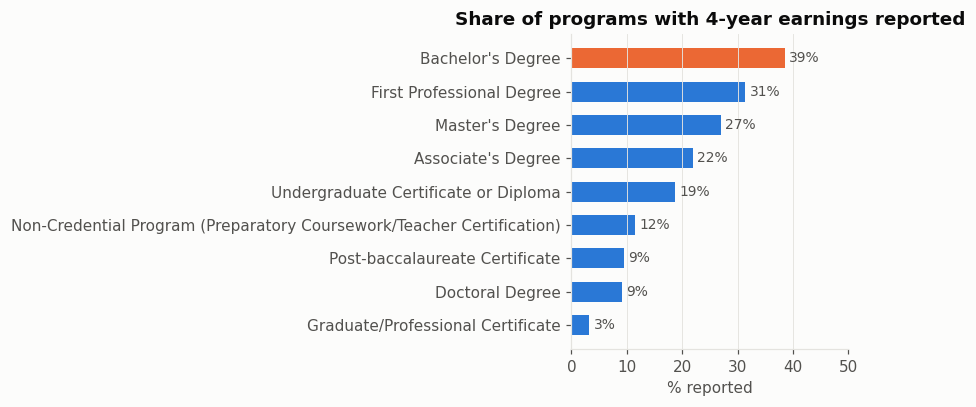

In [5]:
avail = (raw.assign(reported=raw["earnings_4yr_status"].eq("reported"))
            .groupby("credential_name")["reported"].mean().sort_values())

fig, ax = plt.subplots(figsize=(8, 3.8))
colors = [ORANGE if k == "Bachelor's Degree" else BLUE for k in avail.index]
ax.barh(avail.index, avail.values * 100, color=colors, height=0.6)
for i, v in enumerate(avail.values):
    ax.text(v * 100 + 0.8, i, f"{v:.0%}", va="center", fontsize=9, color=INK2)
ax.set(title="Share of programs with 4-year earnings reported", xlabel="% reported", xlim=(0, 50))
ax.grid(axis="y", visible=False)
show(fig, "00_reporting_by_credential.png")

## 2. Data cleaning

Every step records how many rows it removes, so the report can show a clear row-count table.

In [6]:
log = []
def note(step, n_removed, df_now):
    log.append({"step": step, "rows_removed": int(n_removed), "rows_left": len(df_now)})
    print(f"{step:<50} removed {n_removed:>8,}   left {len(df_now):>8,}")

df = raw.copy()
note("Start: all programs", 0, df)

Start: all programs                                removed        0   left  227,980


**2.1 Keep bachelor's degrees** (`credential_level == 3`).

In [7]:
n = len(df); df = df[df["credential_level"] == 3].copy()
note("Keep bachelor's degrees only", n - len(df), df)

Keep bachelor's degrees only                       removed  156,316   left   71,664


**2.2 Keep programs whose 4-year earnings are reported.** Suppressed values are *not* random: they belong to small
programs. We do **not** impute the target, and we note in the report that results apply to programs
large enough to be reported (≥ 16 graduates in the cohort).

In [8]:
print(df["earnings_4yr_status"].value_counts(), "\n")
n = len(df); df = df[df["earnings_4yr_status"] == "reported"].copy()
note("Keep programs with 4-yr earnings reported", n - len(df), df)

earnings_4yr_status
privacy_suppressed    44047
reported              27617
Name: count, dtype: int64 

Keep programs with 4-yr earnings reported          removed   44,047   left   27,617


**2.3 Drop foreign campuses**: no US state, tuition or labor-market context.

In [9]:
n = len(df); df = df[df["institution_control"] != "Foreign"]
note("Drop foreign institutions", n - len(df), df)

Drop foreign institutions                          removed        4   left   27,613


**2.4 Remove repeated branch-campus rows.** When several campuses share one OPEID, the Scorecard reports **one**
earnings figure and copies it onto every campus (flag: `outcomes_shared_across_campuses = 1`).
Left in, one number would be counted up to ~20 times. We keep one row per OPEID × field × earnings value,
preferring the main campus.

In [10]:
key = ["opeid6", "cip_code_4digit", "median_earnings_4yr_usd"]
example = (df[df.outcomes_shared_across_campuses == 1].groupby(key).size()
             .sort_values(ascending=False).head(3))
print("Most-repeated shared figures (rows per identical value):\n", example, "\n")

n = len(df)
df = df.sort_values("is_main_campus", ascending=False).drop_duplicates(key).sort_index()
note("Drop branch-campus copies of shared earnings", n - len(df), df)

Most-repeated shared figures (rows per identical value):
 opeid6  cip_code_4digit  median_earnings_4yr_usd
003329  52.01            65292.0                    19
        42.01            49543.0                    19
001459  11.01            82304.0                    17
dtype: int64 

Drop branch-campus copies of shared earnings       removed    2,330   left   25,283


**2.5 Require the national benchmark** (needed for the classification label) and **2.6 fix impossible zeros** (0 enrollment, $0 tuition, 0% admission are reporting artifacts → set to missing).

In [11]:
n = len(df); df = df.dropna(subset=["national_median_earnings_4yr_usd"])
note("Drop rows missing national benchmark", n - len(df), df)

for c in ["institution_undergrad_enrollment", "institution_tuition_in_state_usd",
          "institution_tuition_out_state_usd", "institution_admission_rate"]:
    z = (df[c] == 0).sum()
    df.loc[df[c] == 0, c] = np.nan
    print(f"0 -> NaN in {c}: {z}")

cleaning_log = pd.DataFrame(log)
cleaning_log.to_csv("bachelors_cleaning_log.csv", index=False)
cleaning_log

Drop rows missing national benchmark               removed        0   left   25,283
0 -> NaN in institution_undergrad_enrollment: 1
0 -> NaN in institution_tuition_in_state_usd: 0
0 -> NaN in institution_tuition_out_state_usd: 0
0 -> NaN in institution_admission_rate: 0


,step,rows_removed,rows_left
0,Start: all programs,0,227980
1,Keep bachelor's degrees only,156316,71664
2,Keep programs with 4-yr earnings reported,44047,27617
3,Drop foreign institutions,4,27613
4,Drop branch-campus copies of shared earnings,2330,25283
5,Drop rows missing national benchmark,0,25283


### 2.7 Leakage check

Some columns are **calculated from the target**, so a model that used them would be "seeing the answer."
We confirm this by rebuilding them from the target; a near-zero difference means they must be excluded.

In [12]:
r1 = ((df.median_earnings_4yr_usd / df.national_median_earnings_4yr_usd - 1) * 100
      - df.earnings_vs_national_pct).abs().max()
r2 = (df.median_debt_usd / df.median_earnings_4yr_usd - df.debt_to_earnings_4yr).abs().max()
print(f"earnings_vs_national_pct rebuilt from target: max difference {r1:.3f} pct-pts")
print(f"debt_to_earnings_4yr     rebuilt from target: max difference {r2:.4f}")

earnings_vs_national_pct rebuilt from target: max difference 0.050 pct-pts
debt_to_earnings_4yr     rebuilt from target: max difference 0.0005


## 3. Target variables

Earnings are **right-skewed**: a few top computer-science and math programs earn $230k+. These are real values,
not errors, so we keep them and model the **log** of earnings, which makes the distribution close to symmetric.

count     25283.0
mean      64090.0
std       20914.0
min       16087.0
25%       49658.0
50%       59166.0
75%       74956.0
max      297029.0
Name: median_earnings_4yr_usd, dtype: float64

Skewness raw: 1.49   |   skewness after log: 0.25


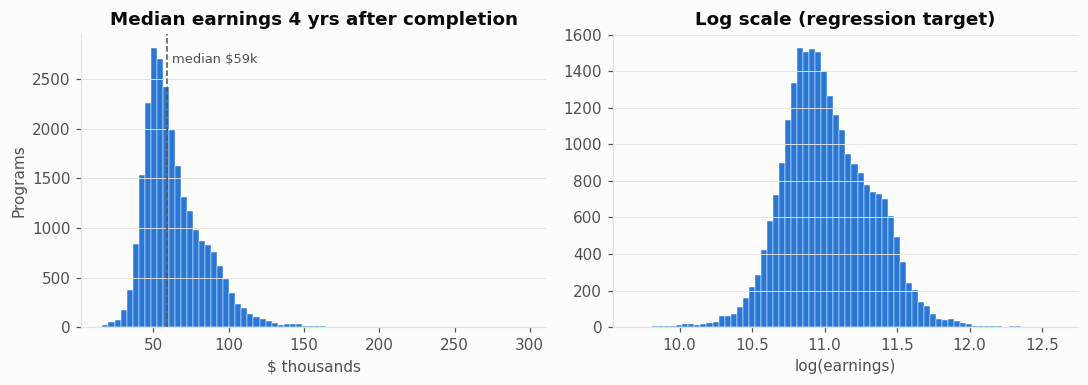

In [13]:
df["target_log_earnings_4yr"] = np.log(df["median_earnings_4yr_usd"])
df["target_above_national"] = (df["earnings_vs_national_pct"] > 0).astype(int)

y = df["median_earnings_4yr_usd"]
print(y.describe().round(0))
print(f"\nSkewness raw: {y.skew():.2f}   |   skewness after log: {df['target_log_earnings_4yr'].skew():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(y / 1000, bins=70, color=BLUE, edgecolor=BG, linewidth=0.3)
axes[0].axvline(y.median() / 1000, color=INK2, linestyle="--", linewidth=1)
axes[0].text(y.median() / 1000 + 3, axes[0].get_ylim()[1] * 0.9, f"median ${y.median()/1000:.0f}k", color=INK2, fontsize=8.5)
axes[0].set(title="Median earnings 4 yrs after completion", xlabel="$ thousands", ylabel="Programs")
axes[1].hist(df["target_log_earnings_4yr"], bins=70, color=BLUE, edgecolor=BG, linewidth=0.3)
axes[1].set(title="Log scale (regression target)", xlabel="log(earnings)")
for a in axes: a.grid(axis="x", visible=False)
show(fig, "01_target_distribution.png")

In [14]:
print("Highest earners (sanity check: plausible, so kept):")
display(df.nlargest(5, "median_earnings_4yr_usd")[["institution_name", "cip_title", "median_earnings_4yr_usd"]])

bal = df["target_above_national"].value_counts(normalize=True).rename({0: "Below national median", 1: "Above national median"})
print("Classification target balance:")
bal.round(3)

Highest earners (sanity check: plausible, so kept):


,institution_name,cip_title,median_earnings_4yr_usd
48798,Duke University,Mathematics,297029.0
25944,Carnegie Mellon University,Computer Science,268121.0
25972,Carnegie Mellon University,"Electrical, Electronics, and Communications En...",250168.0
202311,University of Pennsylvania,"Computer and Information Sciences, General",241380.0
68751,Harvard University,Statistics,230876.0


Classification target balance:


target_above_national
Below national median    0.547
Above national median    0.453
Name: proportion, dtype: float64

The classification classes are **reasonably balanced (≈45 / 55)**, so no resampling is needed.
Accuracy, F1 and ROC-AUC will all be meaningful.

## 4. Feature selection and engineering

### 4.1 Columns excluded (and why)

In [15]:
EXCLUDED = {
    "Other outcomes (leakage)": ["median_earnings_1yr_usd", "median_earnings_5yr_usd",
        "earnings_growth_pct_1yr_to_5yr", "earnings_trajectory_category", "pct_working_5yr",
        "pct_working_in_state_5yr", "pct_above_hs_threshold_5yr", "not_working_count_5yr",
        "count_above_hs_threshold_5yr", "count_working_in_state_5yr"],
    "Computed from target (leakage)": ["earnings_vs_national_pct", "debt_to_earnings_1yr",
        "debt_to_earnings_4yr", "payment_to_income_pct_1yr"],
    "Defined by the earnings measurement": ["earnings_cohort_size_1yr", "earnings_cohort_size_4yr",
        "earnings_cohort_size_5yr", "earnings_4yr_status", "earnings_1yr_status", "earnings_5yr_status", "debt_status"],
    "Redundant / constant": ["national_p25_earnings_4yr_usd", "national_p75_earnings_4yr_usd",
        "median_monthly_payment_usd", "occupation_annual_openings_thousands", "linked_occupations_in_bls",
        "linked_occupations_in_onet", "credential_level", "credential_name", "cip_family_code"],
    "IDs / free text": ["program_id", "unitid", "institution_name", "institution_city", "cip_title",
        "largest_linked_occupation", "largest_linked_occupation_soc", "ai_tool_examples"],
}
pd.DataFrame([(k, len(v), ", ".join(v[:4]) + (" ..." if len(v) > 4 else "")) for k, v in EXCLUDED.items()],
             columns=["Reason", "# columns", "Examples"])

,Reason,# columns,Examples
0,Other outcomes (leakage),10,"median_earnings_1yr_usd, median_earnings_5yr_u..."
1,Computed from target (leakage),4,"earnings_vs_national_pct, debt_to_earnings_1yr..."
2,Defined by the earnings measurement,7,"earnings_cohort_size_1yr, earnings_cohort_size..."
3,Redundant / constant,9,"national_p25_earnings_4yr_usd, national_p75_ea..."
4,IDs / free text,8,"program_id, unitid, institution_name, institut..."


### 4.2 New features

| Feature | How it's built | Why |
|---|---|---|
| `log_awards_avg` | log(1 + average completions over 2 years) | program size; heavy right tail |
| `log_enrollment` | log(1 + undergraduate enrollment) | institution size; heavy right tail |
| `tuition_out_minus_in` | out-of-state − in-state tuition | public-school pricing signal |
| `sat_missing`, `admission_rate_missing` | 1 if value is missing | missing usually = open-admission / test-optional, which is informative |
| `selectivity` | admission-rate bands (<25%, 25–50%, 50–75%, 75–100%, Open/unknown) | easy-to-read nonlinear effect |
| `online` | simplified distance-education category | delivery mode |
| `log_occ_employment` | log(1 + linked-occupation employment) | job-market size; heavy tail |
| `any_ai_occupation` | 1 if any linked occupation uses AI software | AI-exposure flag |
| `log_median_debt`, `debt_missing` | *optional*: debt is known before earnings (not leakage) but missing for ~14% | group decision |

In [17]:
fe = df.copy()
fe["log_awards_avg"] = np.log1p(fe[["awards_year1", "awards_year2"]].mean(axis=1))
fe["log_enrollment"] = np.log1p(fe["institution_undergrad_enrollment"])
fe["tuition_out_minus_in"] = fe["institution_tuition_out_state_usd"] - fe["institution_tuition_in_state_usd"]
fe["sat_missing"] = fe["institution_avg_sat"].isna().astype(int)
fe["admission_rate_missing"] = fe["institution_admission_rate"].isna().astype(int)
sel = pd.cut(fe["institution_admission_rate"], [0, .25, .5, .75, 1.0001],
             labels=["<25%", "25-50%", "50-75%", "75-100%"]).astype(object)
fe["selectivity"] = sel.where(sel.notna(), "Open/unknown")
fe["online"] = fe["distance_education"].map({
    "No credentials fully online": "None", "Some credentials fully online": "Some",
    "All credentials fully online": "All", "Not reported to IPEDS": "Not reported"})
fe["log_occ_employment"] = np.log1p(fe["occupation_employment_2024_thousands"])
fe["any_ai_occupation"] = (fe["occupations_using_ai_software"] > 0).astype(int)
fe["log_median_debt"] = np.log(fe["median_debt_usd"])
fe["debt_missing"] = fe["median_debt_usd"].isna().astype(int)

NUMERIC = [
    # program / institution
    "log_awards_avg", "is_main_campus", "outcomes_shared_across_campuses",
    "log_enrollment", "institution_tuition_in_state_usd", "tuition_out_minus_in",
    "institution_admission_rate", "admission_rate_missing", "institution_avg_sat", "sat_missing",
    "institution_is_hbcu", "institution_latitude", "institution_longitude",
    # field benchmark (national median for this field, bachelor's)
    "national_median_earnings_4yr_usd",
    # labor market
    "linked_occupations_count", "occupation_median_wage_2024_usd", "occupation_growth_pct_2024_34",
    "occupation_growth_pct_max", "log_occ_employment",
    # AI exposure
    "occupations_using_ai_software", "ai_software_occupation_share", "expert_system_occupation_share",
    "ai_tools_max_per_occupation", "hot_technologies_mean_per_occupation", "any_ai_occupation",
]
CATEGORICAL = ["institution_control", "institution_region", "cip_family_title",
               "online", "selectivity", "occupation_typical_entry_education"]
OPTIONAL_NUMERIC = ["log_median_debt", "debt_missing"]   # decide as a group
HIGH_CARD = ["cip_code_4digit", "institution_state"]      # 300+/50+ levels: target-encode inside CV, or leave out
GROUP = "opeid6"                                          # institution id for the grouped split
TARGETS = ["target_log_earnings_4yr", "target_above_national", "median_earnings_4yr_usd"]

print(f"Model features: {len(NUMERIC)} numeric + {len(CATEGORICAL)} categorical = {len(NUMERIC) + len(CATEGORICAL)}")

Model features: 25 numeric + 6 categorical = 31


### 4.3 Missing values in the chosen features

The remaining gaps are modest. They will be **median-imputed inside the model pipeline** (fit on training data
only, so no information leaks from the test set). For SAT and admission rate, the `_missing` flags keep the
fact that a value was missing.

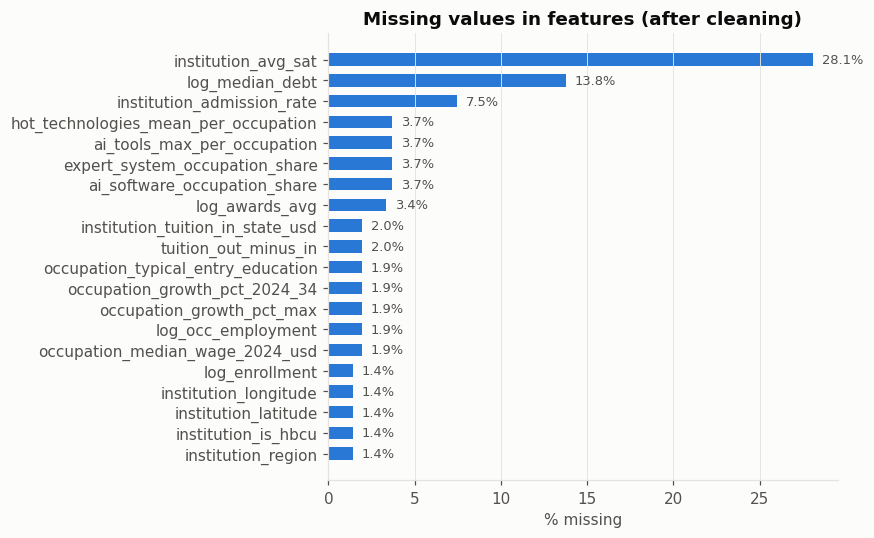

Median earnings by SAT availability (why we keep the flag):
 sat_missing
SAT reported    60041.0
SAT missing     57056.5
Name: median_earnings_4yr_usd, dtype: float64


In [18]:
m = fe[NUMERIC + OPTIONAL_NUMERIC + CATEGORICAL].isna().mean().mul(100)
m = m[m > 0].sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(m.index, m.values, color=BLUE, height=0.6)
for i, v in enumerate(m.values):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=8.5, color=INK2)
ax.set(title="Missing values in features (after cleaning)", xlabel="% missing")
ax.grid(axis="y", visible=False)
show(fig, "02_feature_missingness.png")

r = fe.groupby("sat_missing")["median_earnings_4yr_usd"].median().rename({0: "SAT reported", 1: "SAT missing"})
print("Median earnings by SAT availability (why we keep the flag):\n", r)

## 5. Exploratory data analysis

### 5.1 Field of study: the biggest single driver

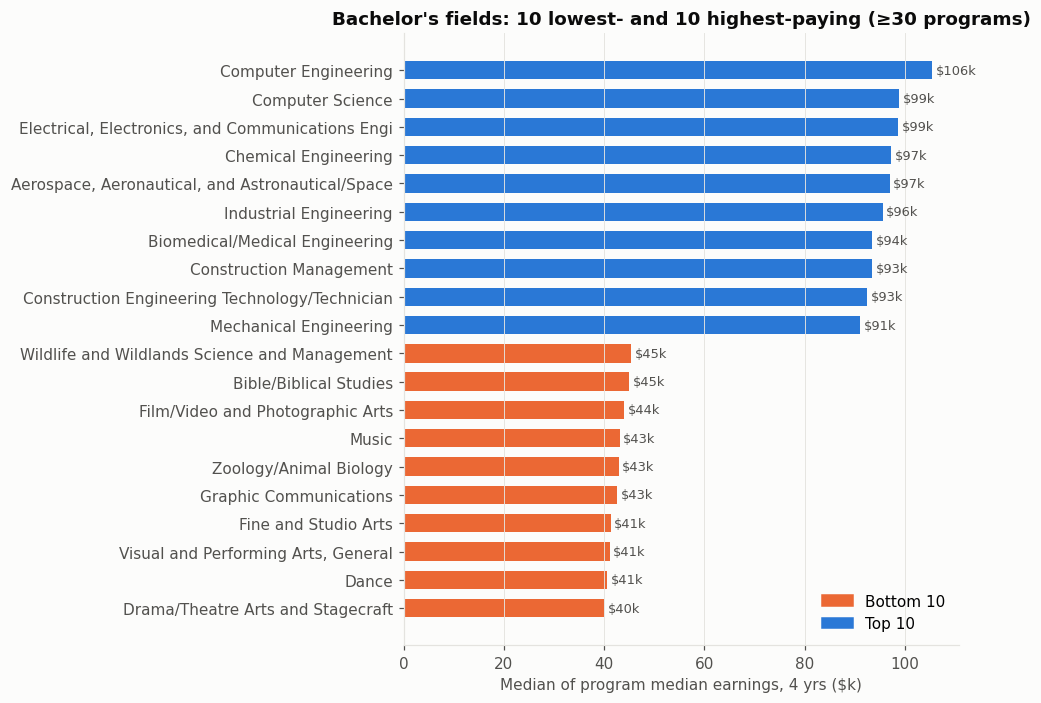

In [19]:
fld = fe.groupby("cip_title")["median_earnings_4yr_usd"].agg(["median", "size"])
fld = fld[fld["size"] >= 30].sort_values("median")
tb = pd.concat([fld.head(10), fld.tail(10)])

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh([t[:48] for t in tb.index], tb["median"] / 1000, color=[ORANGE] * 10 + [BLUE] * 10, height=0.65)
for i, v in enumerate(tb["median"] / 1000):
    ax.text(v + 0.7, i, f"${v:.0f}k", va="center", fontsize=8.5, color=INK2)
ax.set(title="Bachelor's fields: 10 lowest- and 10 highest-paying (≥30 programs)",
       xlabel="Median of program median earnings, 4 yrs ($k)")
ax.grid(axis="y", visible=False)
ax.legend([plt.Rectangle((0, 0), 1, 1, color=ORANGE), plt.Rectangle((0, 0), 1, 1, color=BLUE)],
          ["Bottom 10", "Top 10"], frameon=False, loc="lower right")
show(fig, "03_fields_top_bottom.png")

Engineering and computing fields earn **more than double** the arts and performance fields (~$100k vs ~$40k), four years out.

### 5.2 Institution type and selectivity

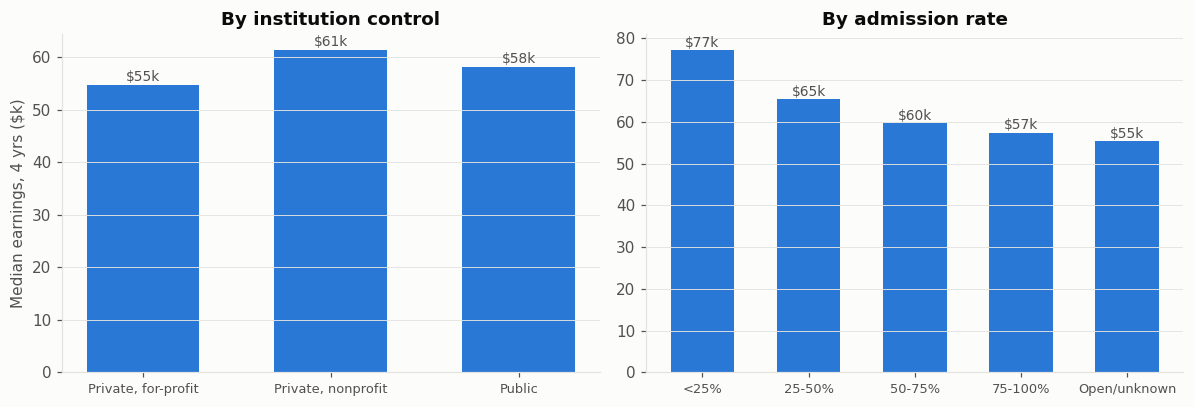

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col, title, order in [
        (axes[0], "institution_control", "By institution control", None),
        (axes[1], "selectivity", "By admission rate", ["<25%", "25-50%", "50-75%", "75-100%", "Open/unknown"])]:
    g = fe.groupby(col)["median_earnings_4yr_usd"].median() / 1000
    if order: g = g.reindex(order)
    ax.bar(g.index, g.values, color=BLUE, width=0.6)
    for x, v in enumerate(g.values):
        ax.text(x, v + 0.8, f"${v:.0f}k", ha="center", fontsize=9, color=INK2)
    ax.set_title(title); ax.grid(axis="x", visible=False); ax.tick_params(axis="x", labelsize=8.5)
axes[0].set_ylabel("Median earnings, 4 yrs ($k)")
show(fig, "04_control_selectivity.png")

Public vs. private makes only a few thousand dollars' difference, but **selectivity** shows a clear gradient:
programs at schools admitting under 25% earn about **$20k more** than those at open or less-selective schools.

### 5.3 How much does the field's national benchmark explain?

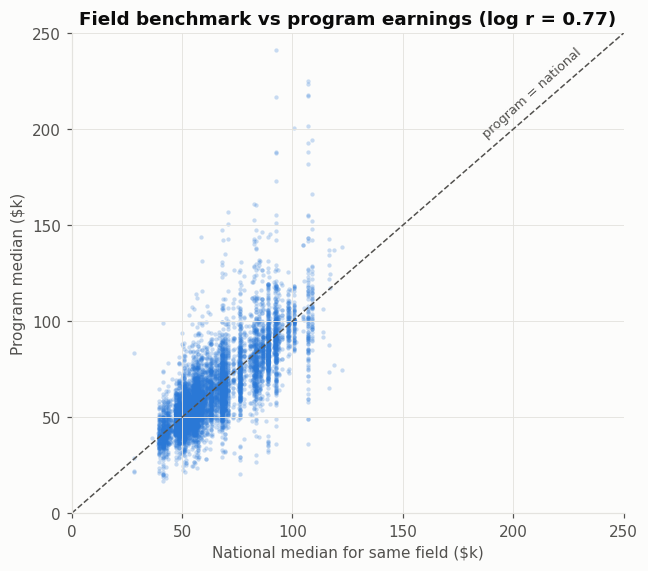

The field benchmark alone explains about 59% of the variance in log earnings.


In [21]:
s = fe.sample(min(8000, len(fe)), random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(6, 5.3))
ax.scatter(s.national_median_earnings_4yr_usd / 1000, s.median_earnings_4yr_usd / 1000,
           s=8, alpha=0.25, color=BLUE, linewidths=0)
lim = [0, 250]
ax.plot(lim, lim, color=INK2, linewidth=1, linestyle="--")
ax.text(185, 196, "program = national", color=INK2, fontsize=8.5, rotation=42)
ax.set_xlim(lim); ax.set_ylim(lim)
rho = np.corrcoef(np.log(fe.national_median_earnings_4yr_usd), fe.target_log_earnings_4yr)[0, 1]
ax.set(title=f"Field benchmark vs program earnings (log r = {rho:.2f})",
       xlabel="National median for same field ($k)", ylabel="Program median ($k)")
show(fig, "05_benchmark_vs_program.png")
print(f"The field benchmark alone explains about {rho**2:.0%} of the variance in log earnings.")

Knowing only the field already explains ~60% of the variation. That makes **"predict the national field median"**
the natural **baseline** every model must beat. The vertical spread around the dashed line is the
institution-level variation the classification target asks about.

### 5.4 Labor market and AI exposure

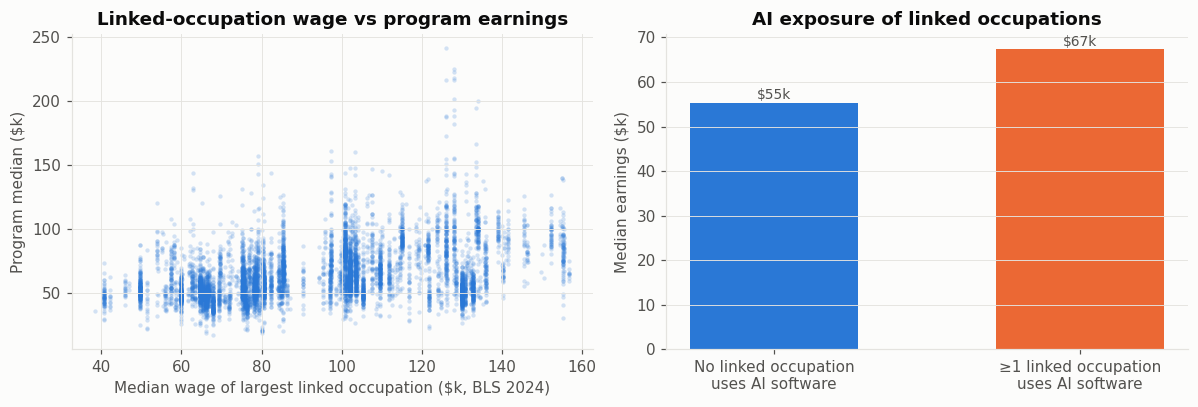

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].scatter(s.occupation_median_wage_2024_usd / 1000, s.median_earnings_4yr_usd / 1000,
                s=8, alpha=0.2, color=BLUE, linewidths=0)
axes[0].set(title="Linked-occupation wage vs program earnings",
            xlabel="Median wage of largest linked occupation ($k, BLS 2024)", ylabel="Program median ($k)")
ai = fe.groupby("any_ai_occupation")["median_earnings_4yr_usd"].median() / 1000
axes[1].bar(["No linked occupation\nuses AI software", "≥1 linked occupation\nuses AI software"],
            ai.values, color=[BLUE, ORANGE], width=0.55)
for x, v in enumerate(ai.values):
    axes[1].text(x, v + 0.8, f"${v:.0f}k", ha="center", fontsize=9, color=INK2)
axes[1].set(title="AI exposure of linked occupations", ylabel="Median earnings ($k)")
axes[1].grid(axis="x", visible=False)
show(fig, "06_labour_market_ai.png")

Programs feeding into higher-wage occupations earn more, and programs linked to **occupations that use AI software
earn about $12k more** at the median. Part of this overlaps with field (computing/engineering), which the models will untangle.

### 5.5 Correlations between numeric features

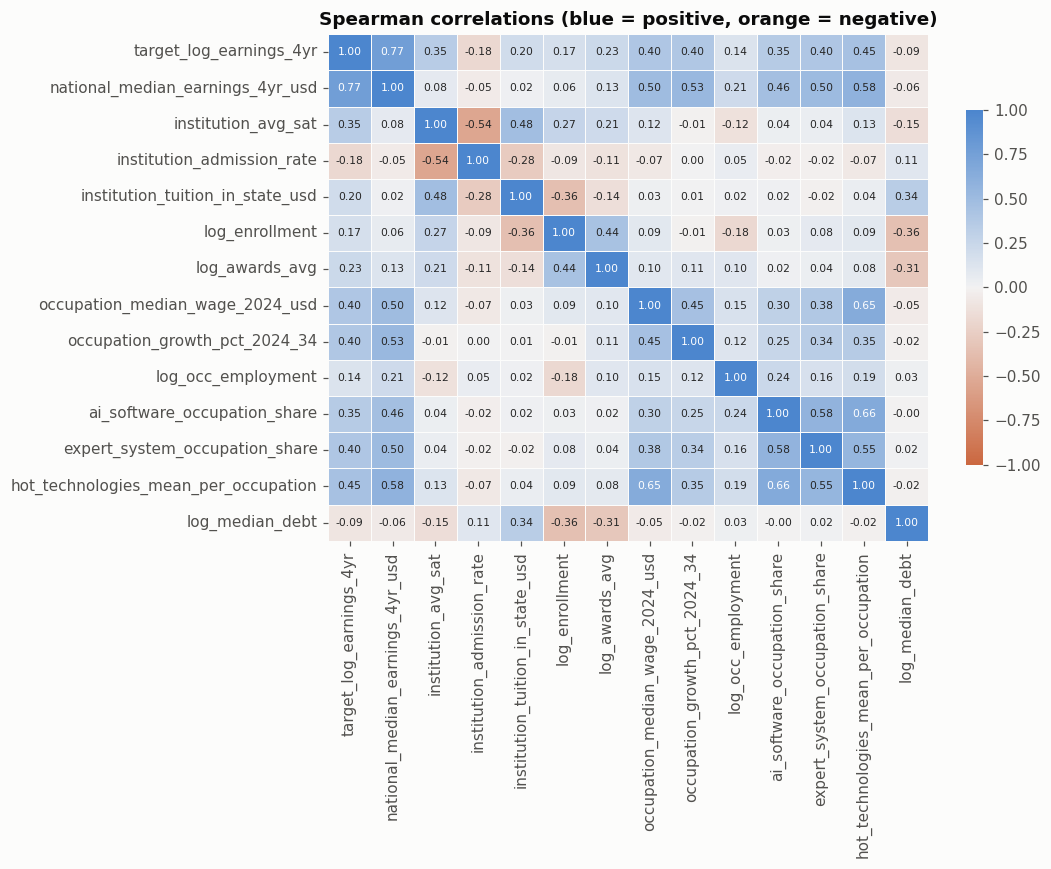

Feature pairs with |rho| > 0.8: none


In [23]:
corr_cols = ["target_log_earnings_4yr", "national_median_earnings_4yr_usd", "institution_avg_sat",
             "institution_admission_rate", "institution_tuition_in_state_usd", "log_enrollment",
             "log_awards_avg", "occupation_median_wage_2024_usd", "occupation_growth_pct_2024_34",
             "log_occ_employment", "ai_software_occupation_share", "expert_system_occupation_share",
             "hot_technologies_mean_per_occupation", "log_median_debt"]
cm = fe[corr_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm, cmap=sns.diverging_palette(25, 250, s=75, l=55, as_cmap=True), center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 7}, linewidths=0.5, linecolor=BG,
            cbar_kws={"shrink": .7}, ax=ax)
ax.set_title("Spearman correlations (blue = positive, orange = negative)"); ax.grid(False)
show(fig, "07_correlations.png")

up = cm.where(np.triu(np.ones(cm.shape, bool), 1)).stack()
print("Feature pairs with |rho| > 0.8:", "none" if not (up.abs() > 0.8).any() else up[up.abs() > 0.8].round(2).to_dict())

- Strongest relationships with the target: **field benchmark (0.77)**, then hot technologies, occupation wage,
  occupation growth and AI-software share (~0.35–0.45), and SAT (0.35).
- **No feature pairs above |0.8|**, so there's no severe multicollinearity after dropping the redundant columns in 4.1.
- Debt is only weakly related to earnings for bachelor's programs (−0.09).

## 6. Train/test split, grouped by institution

The same university appears in many rows. A plain random split would let a model learn "this school pays well"
from training rows and reuse it on test rows from the same school, making scores look better than they are.
We split **by institution (`opeid6`)**, so each school is entirely in train *or* test.
**Use `GroupKFold` with the same groups when tuning hyperparameters.**

In [24]:
model_df = fe[["program_id", GROUP, "institution_name", "cip_title"]
              + TARGETS + NUMERIC + CATEGORICAL + OPTIONAL_NUMERIC + HIGH_CARD].copy()

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(model_df, groups=model_df[GROUP]))
model_df["split"] = "train"
model_df.iloc[test_idx, model_df.columns.get_loc("split")] = "test"

train = model_df[model_df.split == "train"]
test = model_df[model_df.split == "test"]
print(f"Train: {len(train):,} programs from {train[GROUP].nunique():,} institutions")
print(f"Test:  {len(test):,} programs from {test[GROUP].nunique():,} institutions")
print("Institutions in both sets:", len(set(train[GROUP]) & set(test[GROUP])))
print(f"Share above national median: train {train.target_above_national.mean():.3f} | test {test.target_above_national.mean():.3f}")

model_df.to_csv("bachelors_model_ready.csv", index=False)
print("\nSaved bachelors_model_ready.csv")

Train: 19,932 programs from 1,439 institutions
Test:  5,351 programs from 360 institutions
Institutions in both sets: 0
Share above national median: train 0.459 | test 0.430

Saved bachelors_model_ready.csv


## 7. Preprocessing pipeline and baseline

Imputation, scaling and one-hot encoding are wrapped in a single `ColumnTransformer`, **fit on training data only**.
Plug it in front of each model (e.g. `Pipeline([("prep", preprocess), ("model", ...)])`) so all three models get
exactly the same inputs.

In [25]:
preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), NUMERIC),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=30), CATEGORICAL),
])
X_train = preprocess.fit_transform(train)
X_test = preprocess.transform(test)
print(f"X_train: {X_train.shape}   X_test: {X_test.shape}")

# Baseline: predict the national median for the program's field
base_pred = np.log(test["national_median_earnings_4yr_usd"])
print(f"\nBaseline (national field median) on test set:")
print(f"  R² (log earnings) = {r2_score(test.target_log_earnings_4yr, base_pred):.3f}")
print(f"  MAE               = ${mean_absolute_error(test.median_earnings_4yr_usd, test.national_median_earnings_4yr_usd):,.0f}")

X_train: (19932, 88)   X_test: (5351, 88)

Baseline (national field median) on test set:
  R² (log earnings) = 0.566
  MAE               = $8,760


**Example for Section 3 (Model):**
```python
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import GroupKFold, cross_val_score

ridge = Pipeline([("prep", preprocess), ("model", RidgeCV(alphas=np.logspace(-3, 3, 13)))])
scores = cross_val_score(ridge, train, train["target_log_earnings_4yr"],
                         groups=train["opeid6"], cv=GroupKFold(n_splits=5), scoring="r2")
```

## 8. Final dataset

In [26]:
summary = pd.DataFrame({
    "": ["Rows", "Model features", "Columns after one-hot encoding", "Train / test rows", "Train / test institutions"],
    "Value": [f"{raw.shape[0]:,} raw  →  {len(model_df):,} clean bachelor's programs",
              f"{raw.shape[1]} raw columns  →  {len(NUMERIC) + len(CATEGORICAL)} ({len(NUMERIC)} numeric + {len(CATEGORICAL)} categorical)",
              f"{X_train.shape[1]}",
              f"{len(train):,} / {len(test):,}",
              f"{train[GROUP].nunique():,} / {test[GROUP].nunique():,}"],
}).set_index("")
summary

,Value
,
Rows,"227,980 raw → 25,283 clean bachelor's programs"
Model features,72 raw columns → 31 (25 numeric + 6 categori...
Columns after one-hot encoding,88
Train / test rows,"19,932 / 5,351"
Train / test institutions,"1,439 / 360"


## Summary for the report (Section 2: Data)

- **Data:** 227,980 programs from the College Scorecard, joined with BLS occupation data and O\*NET AI-tool data. We focus on **bachelor's programs**.
- **Outcome availability:** about 60% of bachelor's programs have earnings privacy-suppressed; we model the **25,283** programs with reported earnings and note this selection.
- **Cleaning:** kept reported bachelor's programs, removed 4 foreign campuses and **2,330 branch-campus copies** of shared earnings figures, set impossible zeros to missing, and confirmed and removed **leakage** columns derived from the target.
- **Missing data:** median imputation inside the pipeline, plus missing-indicator flags for SAT and admission rate (missing ≈ open admission, and those programs earn less).
- **Skew:** log transform for earnings and for the size/count features; extreme earners kept because they are real.
- **Feature engineering:** program size, tuition gap, selectivity bands, online delivery, AI-exposure flag (31 features → 88 after encoding).
- **EDA takeaways:** field explains most variation (benchmark R² ≈ 0.6); selectivity adds a clear premium; public vs. private matters little; AI-linked and higher-wage occupations pay more.
- **Split:** 80/20 grouped by institution; baseline to beat is R² ≈ 0.57 / MAE ≈ $8.8k.